## 1. Model Training and Evaluation

In this section, five classification algorithms are trained and evaluated to predict machine failures. Stratified 5-fold cross-validation is used to compare model performance on the training data. The models are then evaluated on an independent test set using Accuracy, Precision, Recall, F1-score, and Balanced Accuracy.

In [15]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)



## 1. Load Prepared Datasets

In this section, the prepared training and testing datasets from Milestone 3 are loaded into the notebook. These datasets contain the processed features and the target variable required for machine learning.

## 2. Separate Features and Target

The input features (`X`) are separated from the target variable (`Machine failure`). The training dataset is used to train the models, while the testing dataset is kept separate to evaluate their performance on unseen data.


In [16]:
# Load prepared datasets
train_df = pd.read_csv(
    r"C:\Users\shahd\Documents\GitHub\ai4i-predictive-maintenance\try\data\train_ready_milestone3.csv"
)

test_df = pd.read_csv(
    r"C:\Users\shahd\Documents\GitHub\ai4i-predictive-maintenance\try\data\test_ready_milestone3.csv"
)

# Separate features and target
X_train = train_df.drop("Machine failure", axis=1)
y_train = train_df["Machine failure"]

X_test = test_df.drop("Machine failure", axis=1)
y_test = test_df["Machine failure"]

## Model Selection and Justification

Five classification algorithms were evaluated: Logistic Regression, K-Nearest Neighbors (KNN), Decision Tree, Random Forest, and Gradient Boosting.

The models were compared using 5-fold stratified cross-validation and independent test-set metrics, including Accuracy, Precision, Recall, and F1-score.

The final model was selected based on its mean cross-validated F1-score. F1-score was considered important because predictive maintenance requires a balance between detecting failures and avoiding excessive false alarms.

The final selection should also consider missed failures, operational requirements, and the performance results reported above.

In [17]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced", # give more weight to the data with less visibility 
            random_state=42
        ))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5)) # relay on the nearest 5 nodes
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100, #number of trees the system will build
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100, #number of trees the system will build
        random_state=42
    )
}

# Use the same stratified folds for all models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define the evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

results = []
trained_models = {}
test_predictions = {}

# Train, validate, and evaluate each model
for name, model in models.items():

    print(f"Evaluating: {name}")

    # Evaluate the model using 5-fold cross-validation
    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    # Train the model on the full training set
    model.fit(X_train, y_train)

    # Predict failure on the test set
    y_pred = model.predict(X_test)

    # Save the trained model and its predictions
    trained_models[name] = model
    test_predictions[name] = y_pred

    # Store validation and test results
    results.append({
        "Model": name,
        "CV Accuracy": cv_results["test_accuracy"].mean(),
        "CV Precision": cv_results["test_precision"].mean(),
        "CV Recall": cv_results["test_recall"].mean(),
        "CV F1-score": cv_results["test_f1"].mean(),
        "Test Accuracy": accuracy_score(y_test, y_pred),
        "Test Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Test Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Test F1-score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        )
    })

# Create a comparison table
results_df = pd.DataFrame(results)

# Select the model with the highest cross-validated F1-score
results_df = results_df.sort_values(
    by="CV F1-score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

# Identify the leading model using validation results
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = test_predictions[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: Highest mean 5-fold CV F1-score")

Evaluating: Logistic Regression
Evaluating: KNN
Evaluating: Decision Tree
Evaluating: Random Forest
Evaluating: Gradient Boosting


,Model,CV Accuracy,CV Precision,CV Recall,CV F1-score,Test Accuracy,Test Precision,Test Recall,Test F1-score,Balanced Accuracy
0,Random Forest,0.9705,0.9670,0.9009,0.9327,0.9708,0.9626,0.9067,0.9338,0.9482
1,Gradient Boosting,0.9658,0.9701,0.8767,0.9208,0.9668,0.9691,0.8820,0.9235,0.9369
2,Decision Tree,0.9462,0.8836,0.8794,0.8812,0.9428,0.8645,0.8873,0.8758,0.9232
3,KNN,0.9353,0.9558,0.7499,0.8402,0.9316,0.9501,0.7377,0.8305,0.8631
4,Logistic Regression,0.6993,0.4074,0.7111,0.5179,0.7040,0.4119,0.7077,0.5207,0.7053


Selected model: Random Forest
Selection criterion: Highest mean 5-fold CV F1-score



##  Model Performance Comparison

The performance of the five machine learning models is compared using Test Accuracy, Precision, Recall, and F1-score. This comparison helps identify the strengths and weaknesses of each model and evaluate its ability to detect machine failures. Multiple metrics are considered because Accuracy alone may not adequately reflect performance when failure cases are less frequent.


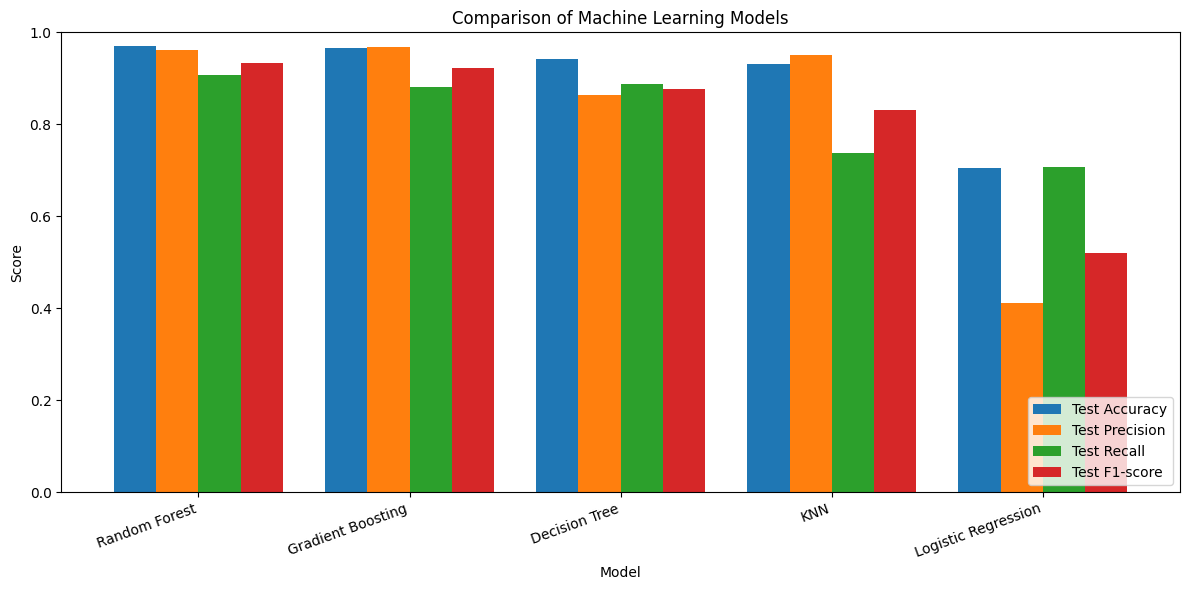

In [18]:

# Compare model performance using multiple metrics

metrics_to_plot = [
    "Test Accuracy",
    "Test Precision",
    "Test Recall",
    "Test F1-score"
]

plot_data = results_df.set_index("Model")[metrics_to_plot]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

ax.set_title("Comparison of Machine Learning Models")
ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()



##  Confusion Matrix and Classification Report

The confusion matrix evaluates the selected model by comparing actual machine failure labels with predicted labels. The classification report provides Precision, Recall, and F1-score for each class.

False negatives represent actual machine failures that the model fails to detect, while false positives represent false failure alerts. These results help assess the model's reliability and understand the potential risks of incorrect predictions in predictive maintenance.


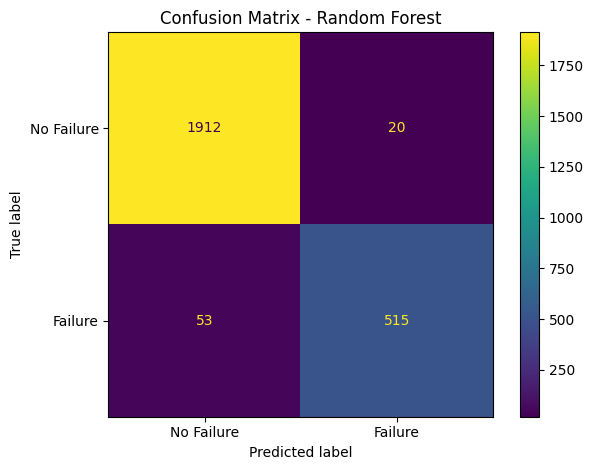

Classification Report: Random Forest

              precision    recall  f1-score   support

  No Failure       0.97      0.99      0.98      1932
     Failure       0.96      0.91      0.93       568

    accuracy                           0.97      2500
   macro avg       0.97      0.95      0.96      2500
weighted avg       0.97      0.97      0.97      2500

True Negatives (correctly predicted no failure): 1912
False Positives (false failure alerts): 20
False Negatives (missed failures): 53
True Positives (correctly detected failures): 515


In [19]:

# Display the confusion matrix for the selected model

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(values_format="d")
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# Print detailed classification metrics
print(f"Classification Report: {best_model_name}\n")

print(classification_report(
    y_test,
    best_predictions,
    labels=[0, 1],
    target_names=["No Failure", "Failure"],
    zero_division=0
))

# Explain the confusion matrix values
tn, fp, fn, tp = cm.ravel()

print("True Negatives (correctly predicted no failure):", tn)
print("False Positives (false failure alerts):", fp)
print("False Negatives (missed failures):", fn)
print("True Positives (correctly detected failures):", tp)



##  Feature Importance Analysis

This section analyzes the importance of input features using the Random Forest model. The importance scores are extracted, sorted, and visualized to identify which features contribute most to the model's predictions of machine failure.

This analysis helps improve model interpretability and provides insights into the machine operating conditions associated with failure predictions. However, feature importance indicates predictive contribution and does not establish a causal relationship.


,Feature,Importance
3,Rotational speed [rpm],0.2006
6,Temp_Diff,0.1951
7,Mechanical_Power_W,0.1593
4,Torque [Nm],0.1447
5,Tool wear [min],0.1276
8,Strain_Index,0.0617
1,Air temperature [K],0.0555
2,Process temperature [K],0.0492
0,Type,0.0063


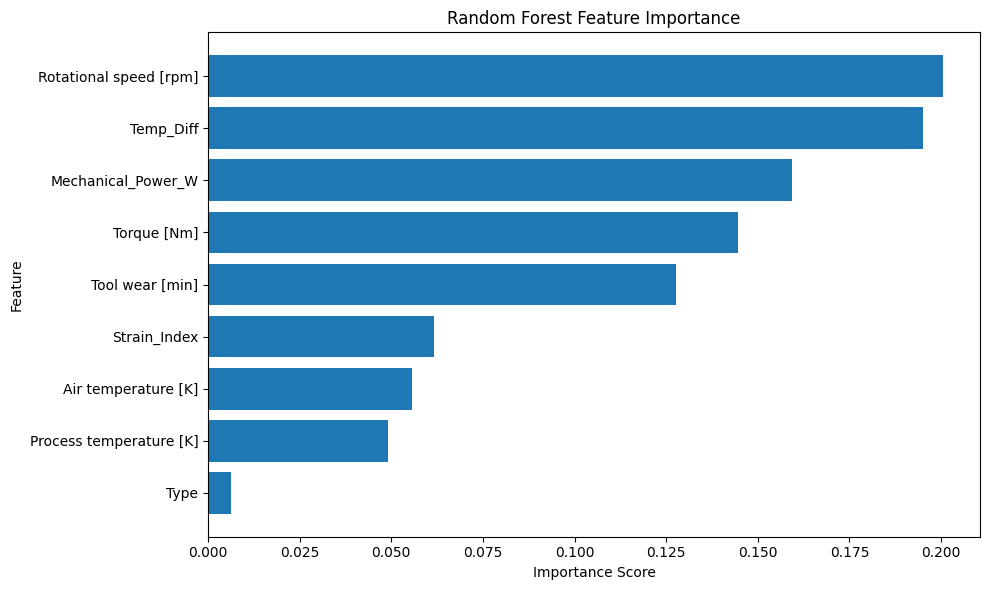

In [20]:

# Extract the Random Forest model for feature importance analysis

rf_model = trained_models["Random Forest"]

# Get feature importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.round(4))

# Plot the most important features
plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"][::-1],
    feature_importance["Importance"][::-1]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



##  Prediction Results and Error Analysis

This section compares the actual machine failure labels with the predictions generated by the selected model. The results are presented in a table showing the actual class, predicted class, and whether each prediction is correct.

The analysis also identifies incorrectly classified cases to help understand the model's limitations and its ability to detect machine failures. Examining these errors can reveal opportunities for improving predictive maintenance performance.


In [21]:

# Compare actual and predicted results
results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": best_predictions
})

# Check correct predictions
results["Correct"] = results["Actual"] == results["Predicted"]

# Display the first 20 predictions
display(results.head(20))

# Count correct and incorrect predictions
print("Correct predictions:", results["Correct"].sum())
print("Incorrect predictions:", (~results["Correct"]).sum())


,Actual,Predicted,Correct
0,1,1,True
1,0,0,True
2,0,0,True
3,0,0,True
4,0,0,True
5,0,0,True
6,0,0,True
7,0,0,True
8,0,0,True
9,0,0,True


Correct predictions: 2427
Incorrect predictions: 73



##  Final Model Evaluation

This section summarizes the performance of the selected machine learning model on the independent test set. The evaluation includes Accuracy, Precision, Recall, F1-score, and Balanced Accuracy, along with the mean F1-score obtained through 5-fold cross-validation.

Random Forest was selected based on its highest mean cross-validated F1-score among the evaluated models. The final metrics provide an overview of its ability to predict machine failures and support the assessment of its suitability for predictive maintenance.


In [22]:

# Retrieve the selected model's test metrics

best_result = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print("=" * 50)
print("FINAL MODEL EVALUATION")
print("=" * 50)

print("Selected model:", best_model_name)
print(f"Cross-validation F1-score: {best_result['CV F1-score']:.4f}")
print(f"Test Accuracy: {best_result['Test Accuracy']:.4f}")
print(f"Test Precision: {best_result['Test Precision']:.4f}")
print(f"Test Recall: {best_result['Test Recall']:.4f}")
print(f"Test F1-score: {best_result['Test F1-score']:.4f}")
print(f"Balanced Accuracy: {best_result['Balanced Accuracy']:.4f}")

print("\nReason for selection:")
print(
    "The model was selected based on its highest mean "
    "5-fold cross-validated F1-score among the evaluated models."
)


FINAL MODEL EVALUATION
Selected model: Random Forest
Cross-validation F1-score: 0.9327
Test Accuracy: 0.9708
Test Precision: 0.9626
Test Recall: 0.9067
Test F1-score: 0.9338
Balanced Accuracy: 0.9482

Reason for selection:
The model was selected based on its highest mean 5-fold cross-validated F1-score among the evaluated models.


# Part 2: Failure Type Classification and Probability

In this part, a second group of models is added beside the existing models. The existing models (Part 1) predict **whether** a machine will fail. The new models predict **which type of failure** will happen.

The two stages are connected as follows:

- **Stage 1:** the selected model from Part 1 gives the probability of *Failure* and *No Failure*.
- **Stage 2:** new multi-label models give the probability of each failure type (TWF, HDF, PWF, OSF, RNF), assuming the machine fails.
- **Decision layer:** the Stage 2 result is shown only when Stage 1 predicts a failure, so the two stages never give conflicting results.

Failure types are **multi-label** because one machine can have more than one failure type at the same time.

## 1. Import Additional Libraries

In [23]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.multioutput import MultiOutputClassifier

## 2. Load the Failure Type Labels

The Milestone 3 files contain only `Machine failure`. The failure types (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) exist in the original dataset, so they are added back to the **same train and test rows**.

Because the Milestone 3 values are scaled, they are first converted back to their original units, then matched with the original dataset. The final check confirms that every row was matched correctly.

In [24]:
# Load the original dataset (contains the failure types)
raw_df = pd.read_csv(
    r"C:\Users\shahd\Documents\GitHub\ai4i-predictive-maintenance\synthetic_data\milestone3\AI4I_with_synthetic_data_cleaned_data.csv"
)
type_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
num_cols = [
    "Air temperature [K]", "Process temperature [K]",
    "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"
]

all_scaled = pd.concat([train_df, test_df], ignore_index=True)

# Convert scaled values back to the original units
def to_original_units(scaled_df):
    original = pd.DataFrame()
    original["Type"] = scaled_df["Type"].map({0: "L", 1: "M", 2: "H"})
    for col in num_cols:
        scaled_values = np.sort(all_scaled[col].unique())
        raw_values = np.sort(raw_df[col].unique())
        std, mean = np.polyfit(scaled_values, raw_values, 1)   # inverse of StandardScaler
        original[col] = ((scaled_df[col] * std + mean) * 100).round().astype(int)
    return original

# Match the rows with the original dataset to get the failure types
raw_keys = raw_df.copy()
for col in num_cols:
    raw_keys[col] = (raw_keys[col] * 100).round().astype(int)

def get_failure_types(scaled_df):
    keys = to_original_units(scaled_df)
    merged = keys.merge(
        raw_keys[["Type"] + num_cols + ["Machine failure"] + type_cols],
        on=["Type"] + num_cols, how="left"
    )
    return merged

train_labels = get_failure_types(train_df)
test_labels = get_failure_types(test_df)

# Check: every row matched and Machine failure is identical
print("Unmatched rows:", train_labels["Machine failure"].isna().sum() + test_labels["Machine failure"].isna().sum())
print("Train labels match:", (train_labels["Machine failure"].values == y_train.values).all())
print("Test labels match:", (test_labels["Machine failure"].values == y_test.values).all())

y_train_types = train_labels[type_cols]
y_test_types = test_labels[type_cols]

print()
print("Failure types in training data:")
print(y_train_types.sum())

Unmatched rows: 0
Train labels match: True
Test labels match: True

Failure types in training data:
TWF    501
HDF    557
PWF    558
OSF    629
RNF    432
dtype: int64


## 3. Check Label Consistency

Some rows in the dataset have inconsistent labels. The failure type model should learn only from reliable failure rows, so these cases are counted before training.

In [25]:
types_count = y_train_types.sum(axis=1)

print("Rows with more than one failure type:", (types_count > 1).sum())
print("Machine failure = 1 but no failure type:", ((y_train == 1) & (types_count == 0)).sum())
print("Machine failure = 0 but a failure type exists:", ((y_train == 0) & (types_count > 0)).sum())

Rows with more than one failure type: 368
Machine failure = 1 but no failure type: 7
Machine failure = 0 but a failure type exists: 14


## 4. Stage 1: Failure Probability

The selected model from Part 1 already supports probabilities (`predict_proba`). The default threshold of 0.5 is not always the best, so the threshold is selected using cross-validation on the **training data only**. The test set is not used.

In [26]:
# Failure probability for each training row (cross-validation)
cv_proba = cross_val_predict(
    best_model, X_train, y_train,
    cv=cv, method="predict_proba"
)[:, 1]

# Select the threshold with the highest F1-score
thresholds = np.arange(0.1, 0.9, 0.02)
best_threshold = max(thresholds, key=lambda t: f1_score(y_train, cv_proba >= t))

print("Stage 1 model:", best_model_name)
print("Selected failure threshold:", round(best_threshold, 2))

Stage 1 model: Random Forest
Selected failure threshold: 0.44


## 5. Stage 2: Train the Failure Type Models

The failure type models learn only one question: *"When a machine fails, which failure type is responsible?"*

Therefore, they are trained only on **reliable failure rows**: `Machine failure = 1` and at least one failure type. `MultiOutputClassifier` trains one model for each failure type, so a machine can have more than one type.

In [27]:
# Keep only reliable failure rows
train_mask = (y_train == 1) & (y_train_types.sum(axis=1) > 0)
test_mask = (y_test == 1) & (y_test_types.sum(axis=1) > 0)

X_train_type = X_train[train_mask]
y_train_type = y_train_types[train_mask]

X_test_type = X_test[test_mask]
y_test_type = y_test_types[test_mask]

print("Stage 2 training rows:", len(X_train_type))
print("Stage 2 test rows:", len(X_test_type))

Stage 2 training rows: 2264
Stage 2 test rows: 566


## Failure Type Model Comparison

Three algorithms are compared using 5-fold cross-validation on the training failure rows, then evaluated on the test failure rows. The micro F1-score is used because it combines all failure types. The model with the highest mean cross-validated micro F1-score is selected.

In [28]:
type_models = {
    "Logistic Regression": MultiOutputClassifier(
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Random Forest": MultiOutputClassifier(
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        )
    ),

    "Gradient Boosting": MultiOutputClassifier(
        GradientBoostingClassifier(
            n_estimators=100,
            random_state=42
        )
    )
}

type_cv = KFold(n_splits=5, shuffle=True, random_state=42)

type_results = []
trained_type_models = {}

for name, model in type_models.items():

    print(f"Evaluating: {name}")

    # Evaluate the model using 5-fold cross-validation
    cv_results = cross_validate(
        model, X_train_type, y_train_type,
        cv=type_cv, scoring="f1_micro", n_jobs=-1
    )

    # Train on all training failure rows
    model.fit(X_train_type, y_train_type)
    trained_type_models[name] = model

    # Predict failure types on the test failure rows
    y_pred_type = model.predict(X_test_type)

    type_results.append({
        "Model": name,
        "CV F1 (micro)": cv_results["test_score"].mean(),
        "Test Precision (micro)": precision_score(y_test_type, y_pred_type, average="micro", zero_division=0),
        "Test Recall (micro)": recall_score(y_test_type, y_pred_type, average="micro", zero_division=0),
        "Test F1 (micro)": f1_score(y_test_type, y_pred_type, average="micro", zero_division=0),
        "Test F1 (macro)": f1_score(y_test_type, y_pred_type, average="macro", zero_division=0)
    })

type_results_df = pd.DataFrame(type_results).sort_values(
    by="CV F1 (micro)", ascending=False
).reset_index(drop=True)

display(type_results_df.round(4))

best_type_model_name = type_results_df.loc[0, "Model"]
best_type_model = trained_type_models[best_type_model_name]

print("Selected failure type model:", best_type_model_name)
print("Selection criterion: Highest mean 5-fold CV micro F1-score")

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: Gradient Boosting


,Model,CV F1 (micro),Test Precision (micro),Test Recall (micro),Test F1 (micro),Test F1 (macro)
0,Gradient Boosting,0.8822,0.9499,0.8346,0.8885,0.8929
1,Random Forest,0.8817,0.9613,0.8300,0.8909,0.8951
2,Logistic Regression,0.6903,0.6082,0.8361,0.7042,0.7029


Selected failure type model: Gradient Boosting
Selection criterion: Highest mean 5-fold CV micro F1-score


## Failure Type Report

The report shows Precision, Recall, and F1-score for each failure type of the selected model, using the real failure rows of the test set.

In [29]:
y_pred_type = best_type_model.predict(X_test_type)

print(f"Classification Report: {best_type_model_name}\n")
print(classification_report(
    y_test_type,
    y_pred_type,
    target_names=type_cols,
    zero_division=0
))

Classification Report: Gradient Boosting

              precision    recall  f1-score   support

         TWF       0.95      0.85      0.90       129
         HDF       0.98      0.85      0.91       144
         PWF       0.96      0.76      0.85       152
         OSF       0.89      0.80      0.85       137
         RNF       0.98      0.95      0.96        97

   micro avg       0.95      0.83      0.89       659
   macro avg       0.95      0.84      0.89       659
weighted avg       0.95      0.83      0.89       659
 samples avg       0.95      0.90      0.91       659



## 6. Connect Both Stages

The final probability of each failure type is calculated as:

`P(type) = P(Failure) x P(type | Failure)`

- `P(Failure)` comes from Stage 1.
- `P(type | Failure)` comes from Stage 2.

The decision layer then gives one consistent result:

- If `P(Failure)` is **below** the threshold → **Normal operation** (no failure type is shown).
- If `P(Failure)` is **above** the threshold and a failure type has probability of at least 0.5 → **Failure with the likely type(s)**.
- If `P(Failure)` is **above** the threshold but no type is clear → **Failure, type uncertain**.

The failure type probabilities are independent, so they are **not** forced to sum to 100%.

In [30]:
def predict_failure_and_type(X_input, threshold=best_threshold, type_threshold=0.5):

    # Stage 1: probability of failure
    p_failure = best_model.predict_proba(X_input)[:, 1]

    # Stage 2: probability of each type, if the machine fails
    p_type_given_failure = np.column_stack([
        estimator.predict_proba(X_input)[:, 1]
        for estimator in best_type_model.estimators_
    ])

    # Overall probability of each failure type
    p_type = p_failure[:, None] * p_type_given_failure

    output = pd.DataFrame({
        "No Failure %": (1 - p_failure) * 100,
        "Failure %": p_failure * 100
    })

    for i, t in enumerate(type_cols):
        output[f"{t} %"] = p_type[:, i] * 100

    # Decision layer
    decisions = []
    for i in range(len(X_input)):
        if p_failure[i] < threshold:
            decisions.append("Normal operation")
        else:
            likely = [t for j, t in enumerate(type_cols) if p_type_given_failure[i, j] >= type_threshold]
            if likely:
                decisions.append("Failure - likely " + " + ".join(likely))
            else:
                decisions.append("Failure - type uncertain")

    output["Decision"] = decisions
    return output

## 7. Final Prediction Results

The two-stage system is applied to the test set. The table shows the failure probability, the probability of each failure type, and the final decision. The actual failure types are added to compare them with the predictions.

In [31]:
final_results = predict_failure_and_type(X_test)

# Add the actual labels for comparison
final_results["Actual Failure"] = y_test.values
final_results["Actual Types"] = y_test_types.apply(
    lambda row: " + ".join([t for t in type_cols if row[t] == 1]) or "None", axis=1
).values

# Display the first 15 machines predicted as failure
display(final_results[final_results["Decision"] != "Normal operation"].head(15).round(1))

print("Decision counts:")
print(final_results["Decision"].value_counts())

,No Failure %,Failure %,TWF %,HDF %,PWF %,OSF %,RNF %,Decision,Actual Failure,Actual Types
0,25.0,75.0,72.8,0.1,6.5,6.2,1.3,Failure - likely TWF,1,TWF
16,1.0,99.0,4.7,2.6,4.6,98.0,0.1,Failure - likely OSF,1,OSF
20,27.0,73.0,0.7,70.8,2.3,2.7,4.2,Failure - likely HDF,1,HDF
22,0.0,100.0,1.5,97.8,3.9,4.6,0.4,Failure - likely HDF,1,HDF
36,0.0,100.0,2.5,12.1,99.4,14.4,0.2,Failure - likely PWF,1,PWF
44,0.0,100.0,1.4,98.9,3.3,6.2,0.4,Failure - likely HDF,1,HDF
47,2.0,98.0,17.1,0.2,2.1,2.5,97.1,Failure - likely RNF,1,RNF
49,13.0,87.0,1.9,11.5,86.3,6.5,0.0,Failure - likely PWF,1,PWF
50,7.0,93.0,4.4,3.9,4.5,89.0,1.0,Failure - likely OSF,1,OSF
52,0.0,100.0,1.3,2.5,99.4,10.6,0.1,Failure - likely PWF,1,PWF


Decision counts:
Decision
Normal operation              1952
Failure - likely HDF           116
Failure - likely TWF           109
Failure - likely PWF           105
Failure - likely OSF           103
Failure - likely RNF            86
Failure - likely PWF + OSF      10
Failure - type uncertain         6
Failure - likely HDF + OSF       6
Failure - likely HDF + PWF       5
Failure - likely TWF + RNF       1
Failure - likely TWF + OSF       1
Name: count, dtype: int64


## Final Two-Stage Evaluation

The Stage 1 decision (using the selected threshold) is evaluated on the full test set, and the Stage 2 result is evaluated on the real failure rows.

In [32]:
stage1_pred = (final_results["Failure %"] / 100 >= best_threshold).astype(int)

print("=" * 50)
print("FINAL TWO-STAGE EVALUATION")
print("=" * 50)

print("Stage 1 model:", best_model_name)
print("Stage 1 threshold:", round(best_threshold, 2))
print(f"Stage 1 Test Precision: {precision_score(y_test, stage1_pred):.4f}")
print(f"Stage 1 Test Recall: {recall_score(y_test, stage1_pred):.4f}")
print(f"Stage 1 Test F1-score: {f1_score(y_test, stage1_pred):.4f}")

best_type_result = type_results_df.iloc[0]
print()
print("Stage 2 model:", best_type_model_name)
print(f"Stage 2 CV micro F1-score: {best_type_result['CV F1 (micro)']:.4f}")
print(f"Stage 2 Test micro F1-score: {best_type_result['Test F1 (micro)']:.4f}")
print(f"Stage 2 Test macro F1-score: {best_type_result['Test F1 (macro)']:.4f}")

FINAL TWO-STAGE EVALUATION
Stage 1 model: Random Forest
Stage 1 threshold: 0.44
Stage 1 Test Precision: 0.9489
Stage 1 Test Recall: 0.9155
Stage 1 Test F1-score: 0.9319

Stage 2 model: Gradient Boosting
Stage 2 CV micro F1-score: 0.8822
Stage 2 Test micro F1-score: 0.8885
Stage 2 Test macro F1-score: 0.8929
